In [42]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

mnist = tf.keras.datasets.mnist #get the dataset

Now we need to clasification data into two groups
1. Training Data
2. Testing Data

In [43]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

Now we going to Normalize the data

Which gives data between 0-1

In [44]:
x_train = tf.keras.utils.normalize(x_train, axis=1)
x_test = tf.keras.utils.normalize(x_test, axis=1)

Now we're going to build the model

In [45]:
model = tf.keras.models.Sequential()
model.add(tf.keras.layers.Flatten(input_shape=(28, 28)))
model.add(tf.keras.layers.Dense(128, activation='relu'))
model.add(tf.keras.layers.Dense(128, activation='relu'))
model.add(tf.keras.layers.Dense(10, activation='softmax'))
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(x_train, y_train, epochs=11)

model.save('handwritten.keras')

model = tf.keras.models.load_model('handwritten.keras')

loss, accuracy = model.evaluate(x_test, y_test)
print("Loss:", loss)
print("Accuracy:", accuracy)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9211 - loss: 0.2699
Epoch 2/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9661 - loss: 0.1085
Epoch 3/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9772 - loss: 0.0731
Epoch 4/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9826 - loss: 0.0537
Epoch 5/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9867 - loss: 0.0410
Epoch 6/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9893 - loss: 0.0326
Epoch 7/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9919 - loss: 0.0250
Epoch 8/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9924 - loss: 0.0223
Epoch 9/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9934 - loss: 0.0184
Epoch 10/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9949 - loss: 0.0152
Epoch 11/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9950 - loss: 0.0137
313/313 ━━━━━━━━━━━━━━━━━━━━ 1

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
File digit_0.png is probably a 0


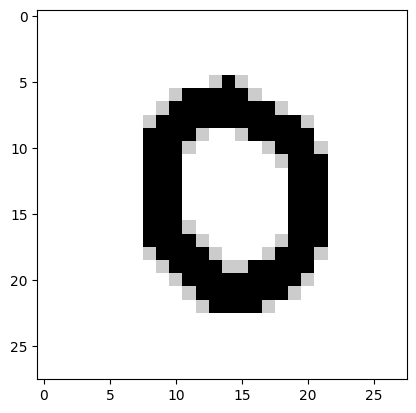

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
File digit_1.png is probably a 1


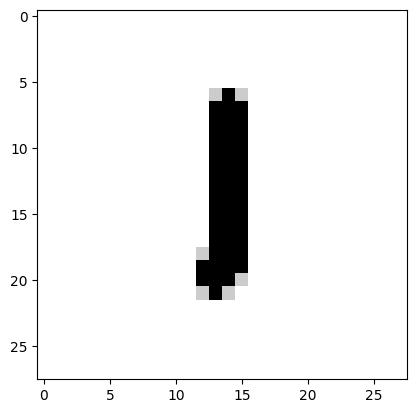

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
File digit_2.png is probably a 2


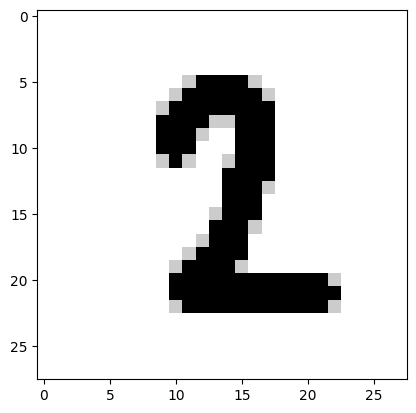

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
File digit_3.png is probably a 3


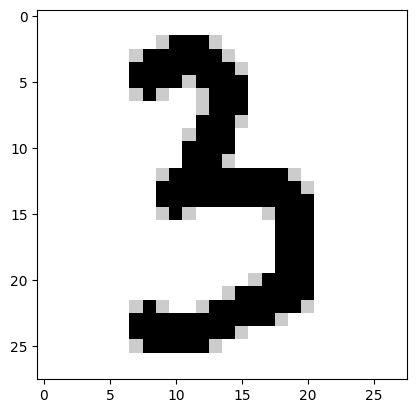

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
File digit_4.png is probably a 4


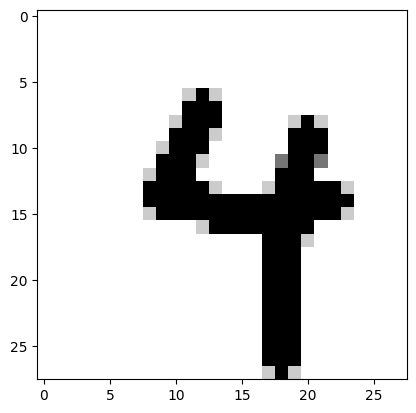

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
File digit_5.png is probably a 3


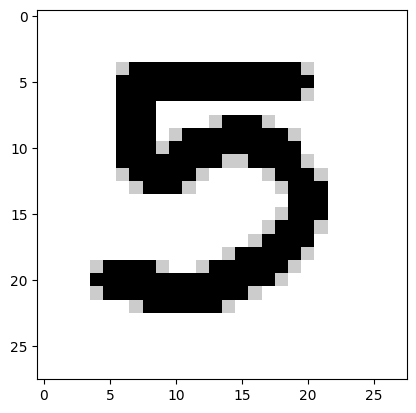

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
File digit_6.png is probably a 5


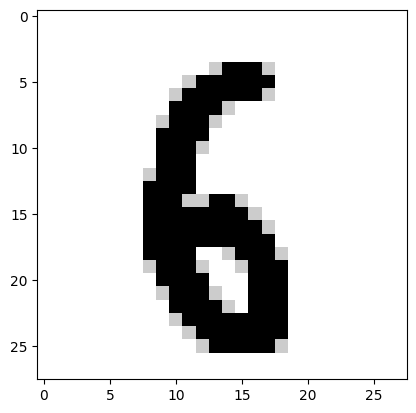

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
File digit_7.png is probably a 7


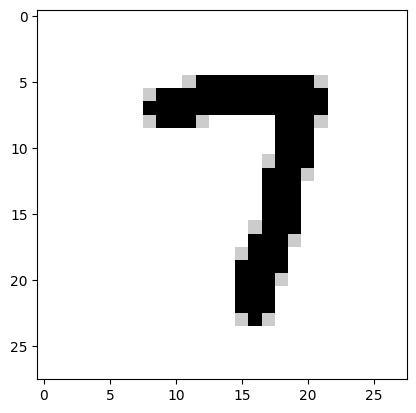

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
File digit_8.png is probably a 8


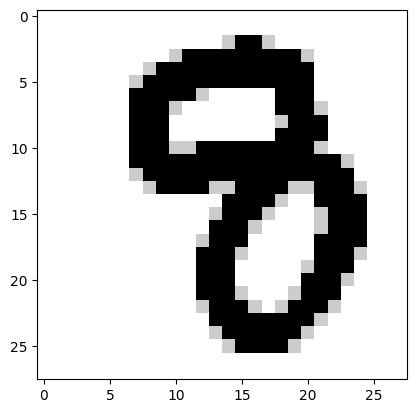

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
File digit_9.png is probably a 3


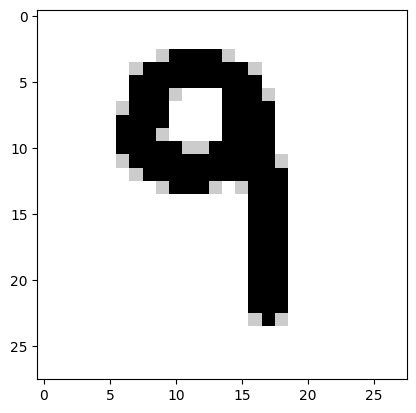

In [46]:
import glob

# Get all PNG images in the sample folder
image_paths = sorted(glob.glob("sample/*.png"))

for img_path in image_paths:
    try:
        # Read and preprocess the image
        img = cv2.imread(img_path)[:,:,0]
        img = np.invert(np.array([img]))

        # Make a prediction
        prediction = model.predict(img)
        print(f"File {os.path.basename(img_path)} is probably a {np.argmax(prediction)}")

        # Display the image
        plt.imshow(img[0], cmap=plt.cm.binary)
        plt.show()
    except Exception as e:
        print(f"Error processing {img_path}: {e}")